<a href="https://colab.research.google.com/github/VintaBytes/Ciencia-de-datos/blob/main/cursos/machine-learning-python/cuadernos/cuaderno-11-evaluacion-de-modelos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"/></a>

# Comparación y evaluación de modelos de Machine Learning

En este cuaderno vamos a trabajar sobre una etapa fundamental de cualquier proyecto de Machine Learning: la comparación de modelos.

Hasta ahora aprendimos a cargar datos, explorarlos, prepararlos, entrenar modelos y evaluar sus resultados. También vimos cómo los `Pipeline` nos permiten organizar el flujo completo de trabajo, integrando el preprocesamiento y el modelo en una misma estructura.

En esta clase vamos a unir esas ideas para responder una pregunta central:

**¿Cómo elegimos el modelo más adecuado para un problema concreto?**

Para hacerlo, no alcanza con mirar una sola métrica. Vamos a comparar distintos modelos utilizando varias herramientas de evaluación, como:

- métricas de clasificación;
- matriz de confusión;
- validación cruzada;
- curva ROC;
- AUC;
- visualizaciones comparativas.

El objetivo no será simplemente encontrar “el modelo que da mejor número”, sino aprender a justificar una decisión técnica a partir de evidencia.

## ¿Por qué comparar modelos?

Cuando resolvemos un problema de Machine Learning, rara vez existe un único modelo posible. Para un mismo conjunto de datos podríamos entrenar una regresión logística, un modelo KNN, un árbol de decisión, un random forest u otros algoritmos.

Cada modelo tiene fortalezas y limitaciones. Algunos son más simples de interpretar, otros pueden lograr mejores resultados, algunos necesitan escalado de variables y otros no, algunos son más rápidos y otros requieren más tiempo de entrenamiento.

Por eso, comparar modelos no significa solamente mirar cuál tiene mayor `accuracy`. Un buen análisis debe considerar varios aspectos:

- qué tan bien predice el modelo;
- qué tipo de errores comete;
- qué tan estable es su rendimiento;
- qué tan fácil es explicar sus decisiones;
- qué costo tendría equivocarse en cada tipo de caso;
- qué tan adecuado es para el contexto del problema.

En este cuaderno vamos a comparar varios modelos bajo condiciones equivalentes. Para eso, usaremos `Pipeline`, de modo que cada modelo tenga un flujo de trabajo claro, ordenado y reproducible.

## De los pipelines a la comparación de modelos

En el cuaderno anterior trabajamos con `Pipeline`, una herramienta de `scikit-learn` que permite encadenar pasos de procesamiento y modelado.

Un pipeline puede incluir, por ejemplo:

1. imputación de valores faltantes;
2. escalado de variables numéricas;
3. codificación de variables categóricas;
4. entrenamiento de un modelo.

Esto es especialmente importante porque evita aplicar transformaciones de manera desordenada o accidentalmente usar información del conjunto de prueba durante el entrenamiento.

En este cuaderno vamos a aprovechar esa lógica. En lugar de entrenar cada modelo por separado y repetir muchas líneas de código, construiremos un pipeline para cada modelo candidato.

La estructura general será:

```text
        datos originales
              ↓
    limpieza inicial mínima
              ↓
separación en entrenamiento y prueba
              ↓
preprocesamiento dentro del pipeline
              ↓
            modelo
              ↓
          evaluación
              ↓
      comparación final
```

De esta manera, todos los modelos serán evaluados de forma más justa y consistente.

## Importación de librerías

Comenzamos importando las librerías que vamos a utilizar durante el cuaderno.

Usaremos `pandas` y `numpy` para trabajar con los datos, `matplotlib` para crear gráficos y varias herramientas de `scikit-learn` para construir pipelines, entrenar modelos y evaluar resultados.

Aunque al principio la lista de importaciones puede parecer extensa, cada grupo cumple una función concreta dentro del flujo de trabajo:

- carga y organización de datos;
- preprocesamiento;
- creación de pipelines;
- entrenamiento de modelos;
- evaluación y comparación.

In [ ]:
# Importamos librerías generales para trabajar con datos
import pandas as pd
import numpy as np

# Importamos matplotlib para realizar gráficos
import matplotlib.pyplot as plt

# Importamos el dataset que vamos a utilizar
from sklearn.datasets import load_breast_cancer

# Herramientas para separar datos y validar modelos
from sklearn.model_selection import train_test_split, cross_validate

# Herramientas para construir pipelines
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Herramientas de preprocesamiento
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Modelos que vamos a comparar
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Métricas de evaluación para clasificación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    make_scorer,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Configuración general para que pandas muestre mejor las tablas
pd.set_option("display.max_columns", None)

## Dataset de trabajo

Para este cuaderno vamos a utilizar el dataset `breast_cancer`, incluido en `scikit-learn`.

Este dataset se usa habitualmente para problemas de clasificación binaria. El objetivo es predecir si un tumor es benigno o maligno a partir de distintas mediciones numéricas obtenidas sobre imágenes de células.

Elegimos este dataset porque nos permite trabajar con un problema donde la comparación de modelos tiene sentido. No solo nos interesa saber cuántos casos acierta el modelo en general, sino también qué tipo de errores comete.

En un contexto de salud, un falso negativo puede ser especialmente delicado: significaría que el modelo predice que un caso no es riesgoso cuando en realidad sí lo era.

De todos modos, trabajaremos este dataset con fines educativos. El objetivo no es construir una herramienta médica real, sino aprender a evaluar y comparar modelos de clasificación.

In [ ]:
# Cargamos el dataset desde scikit-learn
datos = load_breast_cancer()

# Convertimos las variables predictoras en un DataFrame de pandas
df = pd.DataFrame(datos.data, columns=datos.feature_names)

# Agregamos la variable objetivo al DataFrame
df["objetivo"] = datos.target

# Mostramos las primeras filas
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,objetivo
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Al observar las primeras filas vemos que el dataset contiene muchas columnas numéricas. Cada una representa una medición diferente relacionada con las características del tumor.

La columna `objetivo` es la variable que queremos predecir. En este dataset, las clases están codificadas de la siguiente manera:

- `0`: tumor maligno.
- `1`: tumor benigno.

Esto significa que estamos frente a un problema de **clasificación binaria**, porque el modelo debe elegir entre dos clases posibles.

A partir de estas variables, vamos a entrenar distintos modelos y luego compararemos su rendimiento.

## Exploración inicial del dataset

Antes de construir modelos, necesitamos conocer la estructura general de los datos.

En esta etapa vamos a revisar:

- cuántas filas y columnas tiene el dataset;
- qué tipo de datos contiene cada columna;
- si hay valores faltantes;
- cómo está distribuida la variable objetivo.

Esta revisión inicial nos ayuda a decidir qué tipo de preprocesamiento necesitamos aplicar.

In [ ]:
# Revisamos la cantidad de filas y columnas del DataFrame
df.shape

(569, 31)

El resultado anterior nos indica que el dataset tiene 569 filas y 31 columnas.

De esas 31 columnas, 30 corresponden a variables predictoras y 1 corresponde a la variable objetivo.

In [ ]:
# Revisamos información general del DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

Con `df.info()` podemos observar el tipo de dato de cada columna y la cantidad de valores no nulos.

En este caso, todas las variables predictoras son numéricas. Esto simplifica el preprocesamiento, porque no necesitamos codificar variables categóricas.

De todos modos, vamos a mantener la lógica de pipeline porque nos interesa construir un flujo ordenado y reutilizable. En otros datasets, este mismo esquema podría ampliarse para incluir variables categóricas, texto, fechas u otros tipos de datos.

In [ ]:
# Revisamos si existen valores faltantes en cada columna
df.isna().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


El dataset no presenta valores faltantes. Sin embargo, más adelante igualmente vamos a incluir un imputador dentro del pipeline.

Esto puede parecer innecesario para este caso particular, pero tiene un valor práctico: nos permite construir un flujo más robusto. Si en el futuro usamos un dataset similar con algunos valores faltantes, el pipeline ya estará preparado para resolver ese problema sin modificar toda la estructura del código.

Además, incluir el imputador dentro del pipeline ayuda a reforzar una buena práctica: las transformaciones que calculan información a partir de los datos deben ajustarse con el conjunto de entrenamiento, no con todo el dataset completo.

In [ ]:
# Observamos la distribución de la variable objetivo
df["objetivo"].value_counts()

,count
objetivo,
1,357
0,212


El resultado muestra cuántos casos hay de cada clase.

Recordemos que:

- `0` significa tumor maligno;
- `1` significa tumor benigno.

Esta distribución es importante porque, si una clase aparece mucho más que la otra, la métrica `accuracy` puede resultar engañosa. Un modelo podría obtener un porcentaje alto de aciertos simplemente prediciendo con frecuencia la clase mayoritaria.

Por eso, en este cuaderno no vamos a evaluar los modelos solo con `accuracy`, sino también con otras métricas como `precision`, `recall`, `F1-score`, matriz de confusión, curva ROC y AUC.

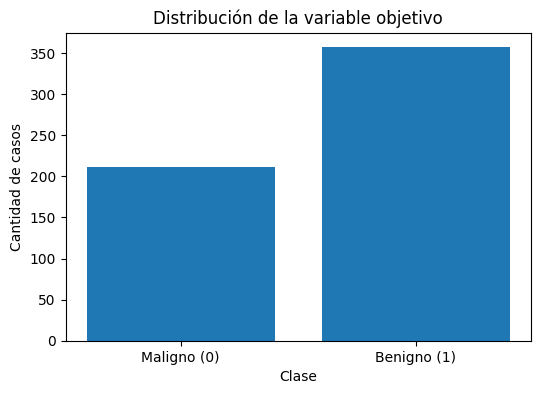

In [ ]:
# Graficamos la distribución de la variable objetivo

conteo_clases = df["objetivo"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["Maligno (0)", "Benigno (1)"], conteo_clases.values)
plt.title("Distribución de la variable objetivo")
plt.xlabel("Clase")
plt.ylabel("Cantidad de casos")
plt.show()

La distribución de clases muestra que hay más casos benignos que malignos:

- `357` casos benignos.
- `212` casos malignos.

Esto significa que el dataset no está perfectamente balanceado. La diferencia no es extrema, pero sí es suficiente para tener cuidado al interpretar los resultados.

Por ejemplo, si un modelo tendiera a predecir con demasiada frecuencia la clase mayoritaria, podría lograr una `accuracy` aparentemente aceptable, pero fallar en casos importantes.

En este problema, además, no todos los errores tienen el mismo peso. Clasificar un tumor maligno como benigno sería un error especialmente delicado. En términos de matriz de confusión, ese caso sería un **falso benigno**, es decir, un caso maligno que el modelo no logró detectar correctamente.

Por eso, más adelante vamos a mirar varias métricas y no solamente el porcentaje general de aciertos.

## Separación entre variables predictoras y variable objetivo

Antes de entrenar modelos, tenemos que separar el dataset en dos partes:

- `X`: contiene las variables predictoras, es decir, las columnas que el modelo usará para aprender.
- `y`: contiene la variable objetivo, es decir, aquello que queremos predecir.

En este caso, todas las columnas excepto `objetivo` serán parte de `X`.

La columna `objetivo` será nuestra variable `y`.

In [ ]:
# Separamos las variables predictoras y la variable objetivo

X = df.drop(columns=["objetivo"])
y = df["objetivo"]

# Revisamos las dimensiones de cada parte
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (569, 30)
Dimensiones de y: (569,)


## Separación en entrenamiento y prueba

Ahora vamos a dividir los datos en dos conjuntos:

- un conjunto de entrenamiento, que el modelo usará para aprender;
- un conjunto de prueba, que usaremos al final para evaluar qué tan bien generaliza el modelo ante datos no vistos.

Esta separación es muy importante. Las transformaciones del pipeline, como el escalado o la imputación, deberán ajustarse usando solamente el conjunto de entrenamiento.

Además, usaremos el parámetro `stratify=y`. Esto permite conservar una proporción similar de casos benignos y malignos tanto en entrenamiento como en prueba.

In [ ]:
# Separamos los datos en entrenamiento y prueba

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Revisamos las dimensiones obtenidas
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
X_test: (114, 30)
y_train: (455,)
y_test: (114,)


La separación generó 455 registros para entrenamiento y 114 registros para prueba.

A partir de este punto debemos tener especial cuidado: cualquier transformación que aprenda información de los datos debe ajustarse solamente con `X_train`.

Por ejemplo, si calculamos una media, una mediana, una desviación estándar o una escala usando todo el dataset, estaríamos dejando que el conjunto de prueba influya indirectamente en el entrenamiento. Eso produciría **data leakage**.

Para evitarlo, vamos a colocar las transformaciones de preparación dentro de un `Pipeline`. De esa manera, `scikit-learn` se encargará de ajustar esas transformaciones solo con los datos de entrenamiento y luego aplicarlas de forma consistente sobre los datos de prueba.

## Construcción del preprocesamiento

En este dataset todas las variables predictoras son numéricas. Por eso, el preprocesamiento será más simple que en otros casos donde también hay variables categóricas.

Aun así, vamos a construir un pipeline de preprocesamiento para las columnas numéricas. Este pipeline incluirá dos pasos:

1. `SimpleImputer`: completa valores faltantes usando la mediana.
2. `StandardScaler`: escala las variables para que tengan una escala comparable.

Aunque este dataset no tiene valores faltantes, incluimos el imputador para mantener un flujo de trabajo robusto y reutilizable.

El escalado es especialmente importante para modelos como KNN y regresión logística. Los árboles de decisión y Random Forest **no necesitan escalado**, porque toman decisiones mediante cortes sobre las variables y no comparan distancias entre observaciones.

En este cuaderno mantendremos un preprocesamiento común para simplificar la comparación. Esto no significa que escalar sea un requisito para todos los algoritmos.

In [ ]:
# Identificamos las columnas numéricas

columnas_numericas = X_train.columns

# Creamos el pipeline para las variables numéricas
pipeline_numericas = Pipeline(
    steps=[
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler())
    ]
)

# Mostramos la cantidad de columnas numéricas
print("Cantidad de columnas numéricas:", len(columnas_numericas))

Cantidad de columnas numéricas: 30


## Integración del preprocesamiento con `ColumnTransformer`

Ahora vamos a crear el objeto `preprocesamiento`.

Para eso usaremos `ColumnTransformer`, una herramienta que permite aplicar distintas transformaciones a distintos grupos de columnas.

En este caso solo tenemos columnas numéricas, por lo que el `ColumnTransformer` aplicará el `pipeline_numericas` a todas las variables predictoras.

Aunque acá parezca una estructura más grande de lo necesario, es una buena práctica porque nos deja preparado el flujo para datasets más complejos. Si en otro problema tuviéramos variables categóricas, podríamos agregar otro pipeline dentro del mismo `ColumnTransformer`.

In [ ]:
# Creamos el preprocesamiento general

preprocesamiento = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numericas, columnas_numericas)
    ]
)

preprocesamiento

ColumnTransformer(transformers=[('numericas',
                                 Pipeline(steps=[('imputador',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalador',
                                                  StandardScaler())]),
                                 Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='object'))])

El objeto `preprocesamiento` ya quedó definido, pero todavía no se aplicó sobre los datos.

Esto es importante: hasta ahora solo construimos la estructura del flujo. El imputador todavía no calculó medianas y el escalador todavía no calculó medias ni desviaciones estándar.

Esas operaciones recién ocurrirán cuando entrenemos un pipeline completo con `.fit()`.

Más adelante, cuando hagamos algo como:

```python
pipeline.fit(X_train, y_train)
```

`scikit-learn` ajustará el preprocesamiento usando solamente `X_train` y luego entrenará el modelo correspondiente.

Esta es una de las principales ventajas de trabajar con pipelines: nos permite definir el proceso completo, pero evita aplicar transformaciones antes de tiempo o de forma desordenada.

## Construcción de los modelos candidatos

Ahora vamos a definir los modelos que queremos comparar.

Trabajaremos con cuatro algoritmos ya conocidos:

- `LogisticRegression`: un modelo lineal, simple e interpretable.
- `KNeighborsClassifier`: un modelo basado en la cercanía entre registros.
- `DecisionTreeClassifier`: un árbol de decisión, capaz de capturar relaciones no lineales.
- `RandomForestClassifier`: un ensamble de muchos árboles de decisión.

También agregaremos un `DummyClassifier` como **baseline**. Este modelo no intenta aprender relaciones complejas: simplemente nos da una referencia mínima contra la cual comparar los modelos reales.

La pregunta que queremos responder es:

> ¿Nuestros modelos realmente superan una estrategia muy simple?

Todavía no vamos a entrenar ninguno. Primero construiremos un pipeline para cada alternativa y luego los compararemos usando únicamente los datos de entrenamiento.

In [ ]:
# Definimos los modelos candidatos que vamos a comparar

modelos = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": LogisticRegression(max_iter=1000, random_state=42),
    "KNN": KNeighborsClassifier(),
    "Árbol de decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# Mostramos los nombres de los modelos definidos
modelos.keys()

dict_keys(['Baseline', 'Regresión logística', 'KNN', 'Árbol de decisión', 'Random Forest'])

## Creación de un pipeline para cada modelo

Ya tenemos definidos los modelos candidatos. Ahora vamos a construir un pipeline completo para cada uno.

Cada pipeline tendrá dos grandes pasos:

1. `preprocesamiento`: aplica las transformaciones necesarias sobre las variables predictoras.
2. `modelo`: entrena el algoritmo correspondiente.

De esta manera, todos los modelos van a recibir los datos preparados con el mismo criterio.

Esto es importante para que la comparación sea más justa. Si cada modelo recibiera datos transformados de una manera distinta, no sabríamos si las diferencias de rendimiento se deben al algoritmo o al preprocesamiento aplicado.

In [ ]:
# Creamos un pipeline completo para cada modelo

pipelines = {}

for nombre_modelo, modelo in modelos.items():
    pipelines[nombre_modelo] = Pipeline(
        steps=[
            ("preprocesamiento", preprocesamiento),
            ("modelo", modelo)
        ]
    )

# Mostramos los nombres de los pipelines creados
pipelines.keys()

dict_keys(['Baseline', 'Regresión logística', 'KNN', 'Árbol de decisión', 'Random Forest'])

Los pipelines ya fueron creados, pero todavía no fueron entrenados.

Hasta este punto tenemos preparada la estructura de trabajo:

```text
datos de entrada
↓
preprocesamiento
↓
modelo
↓
predicción
```

Cada pipeline tiene el mismo paso de preprocesamiento y cambia el algoritmo final.

A partir de ahora seguiremos una regla metodológica importante:

> **El conjunto de prueba no se usará para comparar ni elegir modelos.**

Primero compararemos las alternativas mediante validación cruzada usando solamente `X_train` e `y_train`. Después de seleccionar un modelo, recién entonces utilizaremos `X_test` e `y_test` para realizar la evaluación final.

## Validación cruzada para comparar los modelos

Para elegir entre varios modelos necesitamos estimar cómo se comportan con datos no vistos, pero sin utilizar todavía el conjunto de prueba.

Para eso usaremos **validación cruzada** sobre el conjunto de entrenamiento.

En cada fold, Scikit-learn hará automáticamente lo siguiente:

```text
parte de entrenamiento del fold
        ↓
ajuste del imputador y escalador
        ↓
entrenamiento del modelo
        ↓
evaluación en la parte de validación del fold
```

Como el preprocesamiento está dentro del `Pipeline`, las medianas, medias y desviaciones estándar se calculan nuevamente usando solamente la parte de entrenamiento de cada fold. Esto ayuda a evitar fuga de datos.

No vamos a mirar solo `accuracy`. Como en este problema nos interesa especialmente detectar tumores malignos, también calcularemos `Precision`, `Recall` y `F1-score` tomando la clase `0` como clase positiva de interés.

In [ ]:
# Creamos las métricas que usaremos durante la validación cruzada

scoring = {
    "accuracy": "accuracy",
    "precision_maligno": make_scorer(
        precision_score,
        pos_label=0,
        zero_division=0
    ),
    "recall_maligno": make_scorer(
        recall_score,
        pos_label=0,
        zero_division=0
    ),
    "f1_maligno": make_scorer(
        f1_score,
        pos_label=0,
        zero_division=0
    )
}

## Ejecutamos la validación cruzada

Vamos a evaluar todos los pipelines con `5-fold cross-validation`.

Cada modelo será entrenado cinco veces con distintas divisiones internas de `X_train`. El conjunto `X_test` seguirá completamente reservado.

Guardaremos el promedio y el desvío estándar de las métricas para poder comparar rendimiento y estabilidad.

In [ ]:
# Calculamos validación cruzada para cada pipeline

resultados_cv = []

for nombre_modelo, pipeline in pipelines.items():

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=5,
        scoring=scoring,
        n_jobs=-1
    )

    resultados_cv.append(
        {
            "Modelo": nombre_modelo,
            "CV Accuracy promedio": scores["test_accuracy"].mean(),
            "CV Accuracy desvío": scores["test_accuracy"].std(),
            "CV Precision maligno": scores["test_precision_maligno"].mean(),
            "CV Recall maligno": scores["test_recall_maligno"].mean(),
            "CV F1 maligno": scores["test_f1_maligno"].mean()
        }
    )

# Convertimos los resultados en un DataFrame
df_cv = pd.DataFrame(resultados_cv)

# Ordenamos por F1 de la clase maligna
df_cv = df_cv.sort_values(
    by="CV F1 maligno",
    ascending=False
).reset_index(drop=True)

df_cv

,Modelo,CV Accuracy promedio,CV Accuracy desvío,CV Precision maligno,CV Recall maligno,CV F1 maligno
0,Regresión logística,0.980220,0.012815,0.982828,0.964706,0.973115
1,KNN,0.967033,0.020850,0.969999,0.941176,0.954934
2,Random Forest,0.953846,0.023466,0.946722,0.929412,0.937446
3,Árbol de decisión,0.909890,0.018906,0.883314,0.876471,0.878870
4,Baseline,0.626374,0.000000,0.000000,0.000000,0.000000


La tabla anterior es nuestra herramienta principal para **comparar y seleccionar modelos**.

El `Baseline` alcanza un accuracy cercano a `0.63`, pero obtiene `0` en Precision, Recall y F1 para la clase maligna. Esto ocurre porque, al usar la estrategia `most_frequent`, predice siempre la clase mayoritaria y por lo tanto no detecta ningún caso maligno.

Los modelos reales superan claramente esa referencia.

La **regresión logística** obtiene los mejores resultados de validación cruzada:

- `Accuracy` promedio ≈ **0.980**
- `Precision` para malignos ≈ **0.983**
- `Recall` para malignos ≈ **0.965**
- `F1-score` para malignos ≈ **0.973**

Además, presenta un desvío de accuracy bajo, de aproximadamente `0.013`, lo que indica bastante estabilidad entre folds.

KNN queda en segundo lugar, seguido por Random Forest y luego por el árbol de decisión.

En este ejemplo, la validación cruzada sugiere que la regresión logística es la alternativa más equilibrada para este dataset.

## Visualización de la validación cruzada

Ahora vamos a comparar gráficamente las métricas promedio obtenidas durante la validación cruzada.

El objetivo del gráfico no es reemplazar la tabla, sino facilitar una primera lectura de las diferencias entre modelos.

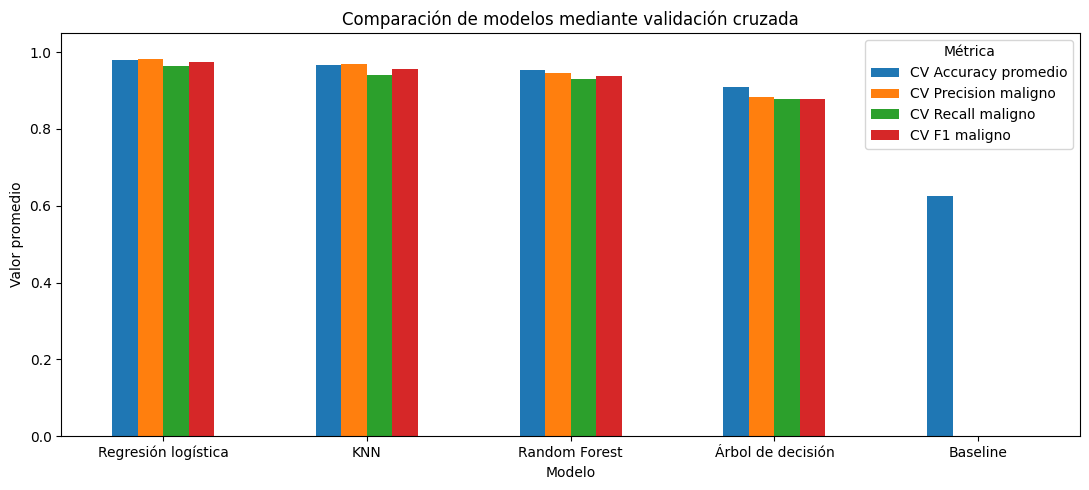

In [ ]:
# Graficamos las principales métricas promedio de validación cruzada

metricas_cv = [
    "CV Accuracy promedio",
    "CV Precision maligno",
    "CV Recall maligno",
    "CV F1 maligno"
]

df_cv_grafico = df_cv.set_index("Modelo")[metricas_cv]

df_cv_grafico.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Comparación de modelos mediante validación cruzada")
plt.xlabel("Modelo")
plt.ylabel("Valor promedio")
plt.ylim(0, 1.05)
plt.xticks(rotation=0, ha="center")
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()

## Selección del modelo

Hasta este momento **no utilizamos el conjunto de prueba**.

Para continuar necesitamos fijar un criterio de selección. En este ejemplo vamos a usar como criterio principal el `F1-score` de la clase maligna obtenido mediante validación cruzada.

Elegimos F1 porque combina dos aspectos importantes:

- detectar los casos malignos (`Recall`);
- evitar marcar demasiados casos benignos como malignos (`Precision`).

Esto es una decisión didáctica para el ejemplo. En un problema real, la métrica prioritaria debería definirse según el contexto y el costo de cada tipo de error.

In [ ]:
# Elegimos el modelo con mayor F1 promedio para la clase maligna

mejor_nombre = df_cv.loc[0, "Modelo"]

print("Modelo seleccionado según CV F1 maligno:")
print(mejor_nombre)

Modelo seleccionado según CV F1 maligno:
Regresión logística


El modelo seleccionado fue **Regresión logística**.

La elección se realizó utilizando únicamente la información disponible dentro del conjunto de entrenamiento y tomando como criterio principal el `F1-score` promedio de la clase maligna.

A partir de este momento consideramos esa elección cerrada.

Ahora sí podemos usar el conjunto de prueba para responder una pregunta distinta:

> ¿Cómo se comporta el modelo elegido frente a datos que no participaron ni del entrenamiento ni de la selección?

Esta será nuestra **evaluación final**.

## Entrenamiento final del modelo seleccionado

La validación cruzada entrenó varias copias temporales de cada pipeline, pero esas copias se utilizaron solamente para estimar rendimiento.

Ahora tomaremos el pipeline correspondiente al modelo seleccionado y lo entrenaremos nuevamente utilizando **todo el conjunto de entrenamiento**.

In [ ]:
# Recuperamos el pipeline del modelo seleccionado

modelo_final = pipelines[mejor_nombre]

# Entrenamos el pipeline usando todo el conjunto de entrenamiento

modelo_final.fit(X_train, y_train)

print("Modelo final entrenado:", mejor_nombre)

Modelo final entrenado: Regresión logística


## Evaluación final sobre el conjunto de prueba

Recién ahora utilizaremos `X_test` e `y_test`.

Calcularemos las métricas principales tomando nuevamente como clase de interés a los tumores malignos (`0`).

Estos resultados ya no se utilizarán para volver atrás y elegir otro modelo. Si hiciéramos eso, el conjunto de prueba dejaría de cumplir su función como evaluación final independiente.

In [ ]:
# Generamos predicciones finales sobre el conjunto de prueba

y_pred_final = modelo_final.predict(X_test)

# Calculamos las métricas finales

accuracy_final = accuracy_score(y_test, y_pred_final)
precision_final = precision_score(
    y_test,
    y_pred_final,
    pos_label=0,
    zero_division=0
)
recall_final = recall_score(
    y_test,
    y_pred_final,
    pos_label=0,
    zero_division=0
)
f1_final = f1_score(
    y_test,
    y_pred_final,
    pos_label=0,
    zero_division=0
)

# Mostramos una tabla compacta

df_resultado_final = pd.DataFrame(
    {
        "Métrica": [
            "Accuracy",
            "Precision maligno",
            "Recall maligno",
            "F1 maligno"
        ],
        "Valor": [
            accuracy_final,
            precision_final,
            recall_final,
            f1_final
        ]
    }
)

df_resultado_final

,Métrica,Valor
0,Accuracy,0.982456
1,Precision maligno,0.976190
2,Recall maligno,0.976190
3,F1 maligno,0.976190


La evaluación final confirma un rendimiento muy alto de la regresión logística:

- `Accuracy` ≈ **0.982**
- `Precision` para malignos ≈ **0.976**
- `Recall` para malignos ≈ **0.976**
- `F1-score` para malignos ≈ **0.976**

Los cuatro valores son altos y, además, están muy equilibrados.

El `Recall` de aproximadamente `0.976` significa que el modelo detectó correctamente casi todos los casos malignos del conjunto de prueba.

En este problema, esa métrica es especialmente importante porque un caso maligno clasificado como benigno representa un error potencialmente más delicado que una falsa alarma.

## Reporte de clasificación del modelo final

El `classification_report` permite observar las métricas separadas para cada clase.

A diferencia de la etapa de comparación anterior, ahora analizaremos solamente el modelo que ya fue seleccionado.

In [ ]:
print("Modelo final:", mejor_nombre)
print()

print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=["Maligno (0)", "Benigno (1)"],
        zero_division=0
    )
)

Modelo final: Regresión logística

              precision    recall  f1-score   support

 Maligno (0)       0.98      0.98      0.98        42
 Benigno (1)       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## Matriz de confusión del modelo final

La matriz de confusión permite ver exactamente qué tipo de errores cometió la regresión logística.

En el conjunto de prueba había:

- 42 casos malignos;
- 72 casos benignos.

El modelo clasificó correctamente:

- **41 de los 42 malignos**;
- **71 de los 72 benignos**.

Cometió solamente dos errores:

- 1 caso maligno fue clasificado como benigno;
- 1 caso benigno fue clasificado como maligno.

Esto explica por qué Precision y Recall para la clase maligna toman exactamente el mismo valor, aproximadamente `0.976`.

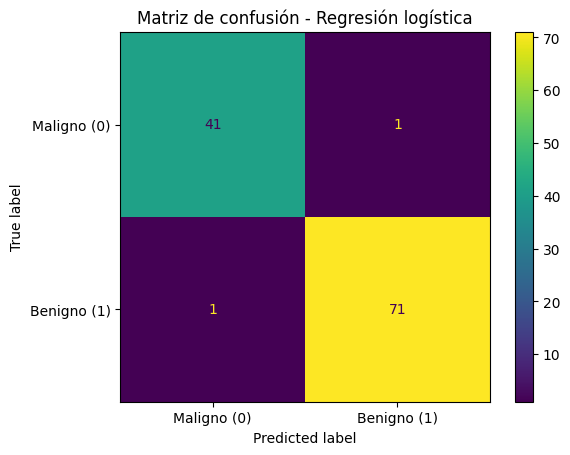

In [ ]:
# Calculamos la matriz de confusión

matriz = confusion_matrix(
    y_test,
    y_pred_final
)

# La graficamos

display = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Maligno (0)", "Benigno (1)"]
)

display.plot()

plt.title(f"Matriz de confusión - {mejor_nombre}")
plt.show()

## Curva ROC y AUC del modelo final

Además de predecir una clase, los modelos utilizados en este cuaderno pueden producir probabilidades mediante `predict_proba()`.

La curva ROC permite estudiar cómo cambia el comportamiento del clasificador al modificar el umbral de decisión.

El valor **AUC** resume la capacidad del modelo para separar las dos clases.

Como en este ejercicio nos interesa especialmente la clase `0` (maligno), convertiremos temporalmente el problema para que:

```text
1 = maligno
0 = benigno
```

y utilizaremos la probabilidad que el modelo asigna a la clase original `0`.

In [ ]:
# Convertimos y_test para considerar "maligno" como clase positiva

y_test_maligno = (y_test == 0).astype(int)

# Buscamos la columna de predict_proba correspondiente a la clase 0

clases = modelo_final.named_steps["modelo"].classes_
indice_clase_0 = list(clases).index(0)

# Obtenemos la probabilidad de malignidad

probabilidades = modelo_final.predict_proba(X_test)
probabilidad_maligno = probabilidades[:, indice_clase_0]

# Calculamos AUC y los puntos de la curva ROC

auc_final = roc_auc_score(
    y_test_maligno,
    probabilidad_maligno
)

fpr, tpr, umbrales = roc_curve(
    y_test_maligno,
    probabilidad_maligno
)

print("AUC del modelo final:", auc_final)

AUC del modelo final: 0.9953703703703705


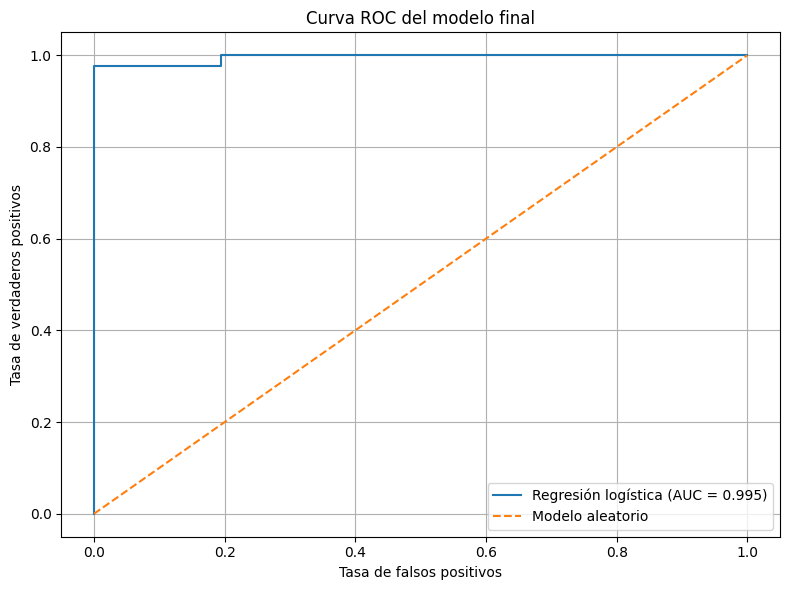

In [ ]:
# Graficamos la curva ROC del modelo final

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"{mejor_nombre} (AUC = {auc_final:.3f})"
)

# Línea de referencia de un clasificador aleatorio
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Modelo aleatorio"
)

plt.title("Curva ROC del modelo final")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Comparación entre validación y prueba

Ahora podemos comparar el rendimiento estimado durante validación cruzada con el resultado obtenido en el conjunto de prueba.

La comparación es especialmente interesante porque ambos resultados son muy próximos:

- `Accuracy`: CV ≈ `0.980` — test ≈ `0.982`
- `Precision maligno`: CV ≈ `0.983` — test ≈ `0.976`
- `Recall maligno`: CV ≈ `0.965` — test ≈ `0.976`
- `F1 maligno`: CV ≈ `0.973` — test ≈ `0.976`

No hacemos esta comparación para volver a elegir el modelo, sino para analizar si la estimación de validación cruzada fue coherente con la evaluación final.

In [ ]:
# Recuperamos los resultados de validación del modelo elegido

fila_cv_final = df_cv[
    df_cv["Modelo"] == mejor_nombre
].iloc[0]

comparacion_validacion_test = pd.DataFrame(
    {
        "Métrica": [
            "Accuracy",
            "Precision maligno",
            "Recall maligno",
            "F1 maligno"
        ],
        "Promedio CV": [
            fila_cv_final["CV Accuracy promedio"],
            fila_cv_final["CV Precision maligno"],
            fila_cv_final["CV Recall maligno"],
            fila_cv_final["CV F1 maligno"]
        ],
        "Test final": [
            accuracy_final,
            precision_final,
            recall_final,
            f1_final
        ]
    }
)

comparacion_validacion_test

,Métrica,Promedio CV,Test final
0,Accuracy,0.980220,0.982456
1,Precision maligno,0.982828,0.976190
2,Recall maligno,0.964706,0.976190
3,F1 maligno,0.973115,0.976190


Los valores de test resultaron muy cercanos a los promedios obtenidos durante validación cruzada.

Eso es una buena señal: la evaluación final no muestra un salto inesperado respecto de lo que habíamos estimado usando solamente el conjunto de entrenamiento.

Incluso el `Recall` para malignos resultó ligeramente superior en test (`≈ 0.976`) al promedio observado durante validación cruzada (`≈ 0.965`).

Esto no significa que el modelo vaya a mantener exactamente esos valores con cualquier muestra futura, pero sí indica que, en este ejercicio, el proceso de selección produjo una estimación consistente.

## Toma de decisión e interpretación

La validación cruzada llevó a seleccionar **Regresión logística** antes de observar el conjunto de prueba.

Luego, la evaluación final confirmó esa elección:

- `Accuracy` ≈ **0.982**
- `F1-score` para malignos ≈ **0.976**
- solo **2 errores** sobre 114 observaciones de prueba;
- AUC ≈ **0.995**

El valor AUC cercano a `1` indica una capacidad muy alta para separar malignos y benignos según las probabilidades producidas por el modelo.

También resulta importante que los resultados de test sean muy próximos a los obtenidos durante validación cruzada. Esto muestra una buena coherencia entre la estimación realizada en entrenamiento y el comportamiento observado finalmente en test.

Para este dataset y con estas configuraciones, la regresión logística aparece como una alternativa muy sólida, además de relativamente simple e interpretable.

## Limitaciones del análisis

Aunque el procedimiento utilizado permite realizar una comparación más ordenada, todavía existen limitaciones.

- Trabajamos con un dataset relativamente pequeño y muy limpio.
- Los modelos se utilizaron con configuraciones simples; todavía no realizamos ajuste sistemático de hiperparámetros.
- Elegimos `F1-score` de la clase maligna como criterio de selección por motivos didácticos. En un problema real podría ser más importante priorizar `Recall`, `Precision`, AUC u otra métrica.
- Mantuvimos un preprocesamiento común para simplificar el ejemplo, aunque árboles de decisión y Random Forest no requieren escalado.
- No ajustamos el umbral de decisión.
- Este análisis tiene fines educativos y no debe interpretarse como una herramienta médica real.

Un paso posterior natural sería utilizar `GridSearchCV` para comparar hiperparámetros sin tocar el conjunto de prueba.

----

## Buenas prácticas al comparar modelos

Al comparar modelos de Machine Learning, conviene tener en cuenta algunas buenas prácticas:

- Separar el conjunto de prueba al comienzo y reservarlo hasta la evaluación final.
- No elegir modelos ni hiperparámetros mirando resultados de test.
- Aplicar las transformaciones que aprenden parámetros usando solamente datos de entrenamiento.
- Usar `Pipeline` cuando resulte conveniente para encapsular preprocesamiento y modelo.
- Comparar modelos mediante validación cruzada sobre el conjunto de entrenamiento.
- No elegir un modelo solamente por `accuracy`.
- Definir métricas acordes al objetivo del problema.
- Incluir un baseline para comprobar si el modelo aporta valor.
- Observar qué tipo de errores comete el modelo elegido.
- Justificar la elección final con evidencia.

----

## ¿Cómo seguir?

A partir del análisis realizado, se puede continuar explorando el problema con alguna de las siguientes modificaciones:

1. Cambiar la métrica utilizada para seleccionar el modelo y observar si cambia la elección.
2. Priorizar `Recall` de la clase maligna y comparar el resultado con la selección por `F1-score`.
3. Agregar otro algoritmo de clasificación.
4. Ajustar hiperparámetros mediante `GridSearchCV`.
5. Analizar diferentes umbrales de decisión para el modelo final.
6. Comparar pipelines con preprocesamientos específicos para cada tipo de modelo.

En todos los casos debe mantenerse la misma regla:

> el conjunto de prueba permanece reservado hasta que todas las decisiones de selección y ajuste hayan sido tomadas.

----

## Cierre

En este cuaderno trabajamos el proceso de comparación y evaluación de varios modelos de clasificación.

Primero se separó un conjunto de prueba que quedó reservado. Después se construyeron pipelines y se compararon los modelos mediante validación cruzada usando solamente los datos de entrenamiento.

La selección se realizó a partir del `F1-score` de la clase maligna. La **regresión logística** obtuvo el mejor promedio de validación cruzada, con un F1 cercano a `0.973`.

Recién después de esa elección se utilizó el conjunto de prueba. Allí el modelo alcanzó un accuracy de aproximadamente `0.982`, un F1 para malignos de aproximadamente `0.976` y un AUC cercano a `0.995`.

La matriz de confusión mostró solamente dos errores: un caso maligno clasificado como benigno y un caso benigno clasificado como maligno.

La idea central del cuaderno puede resumirse así:

```text
          train
            ↓
    validación cruzada
            ↓
        comparación
            ↓
        selección
            ↓
   entrenamiento final
            ↓
      test una sola vez
            ↓
      interpretación
```

Este orden permite evaluar modelos de manera más confiable y reduce el riesgo de tomar decisiones influenciadas por el conjunto de prueba.

---

### Autoría y atribución

Este cuaderno forma parte del material educativo desarrollado por **VintaBytes**.

📧 **Contacto:** [vintabytes@gmail.com](mailto:vintabytes@gmail.com)

🌐 **Repositorio oficial:** [github.com/VintaBytes/Ciencia-de-datos](https://github.com/VintaBytes/Ciencia-de-datos)

Se permite compartir y reutilizar este material respetando la autoría y manteniendo visible esta atribución.

---
